In [53]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.tree import plot_tree


In [54]:
df = pd.read_csv("Admission_predict.csv")
print(df.shape)
df.head()

(400, 9)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [55]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,200.500000,316.807500,107.410000,3.087500,3.400000,3.452500,8.598925,0.547500,0.724350
std,115.614301,11.473646,6.069514,1.143728,1.006869,0.898478,0.596317,0.498362,0.142609
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.000000,6.800000,0.000000,0.340000
25%,100.750000,308.000000,103.000000,2.000000,2.500000,3.000000,8.170000,0.000000,0.640000
50%,200.500000,317.000000,107.000000,3.000000,3.500000,3.500000,8.610000,1.000000,0.730000
75%,300.250000,325.000000,112.000000,4.000000,4.000000,4.000000,9.062500,1.000000,0.830000
max,400.000000,340.000000,120.000000,5.000000,5.000000,5.000000,9.920000,1.000000,0.970000


In [56]:
print(df.columns.tolist())

['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR ', 'CGPA', 'Research', 'Chance of Admit ']


In [57]:
threshold = df["Chance of Admit "].quantile(0.75)
df["Admission"] = (df["Chance of Admit "] >= threshold).astype(int) 
X = df.drop(columns=["Chance of Admit ", "Admission"])
y = df["Admission"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(320, 8) (80, 8)


In [58]:
tree1 = DecisionTreeClassifier(criterion = "gini" , random_state=42)
tree1.fit(X_train, y_train)
pred_tree1 = tree1.predict(X_test)

In [59]:
tree2 = DecisionTreeClassifier(criterion = "entropy" , random_state=42)
tree2.fit(X_train, y_train)
pred_tree2 = tree2.predict(X_test)

In [60]:
nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

In [61]:
def get_scores(y_true, y_pred):
    return [accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred),
            recall_score(y_true, y_pred),
            f1_score(y_true, y_pred)]

result = pd.DataFrame({
    "Metrics :": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Decision Tree :": get_scores(y_test, pred_tree),
    "Naive Bayes :": get_scores(y_test, pred_nb),
})

print(result.round(4))

   Metrics :  Decision Tree :  Naive Bayes :
0   Accuracy           0.9125         0.9375
1  Precision           0.9130         0.8889
2     Recall           0.8077         0.9231
3   F1-score           0.8571         0.9057


In [62]:
print("Decision Tree Confusion matrix")
print(confusion_matrix(y_test, pred_tree))
print("Naive Bayes confusion matrix")
print(confusion_matrix(y_test, pred_nb))

Decision Tree Confusion matrix
[[52  2]
 [ 5 21]]
Naive Bayes confusion matrix
[[51  3]
 [ 2 24]]


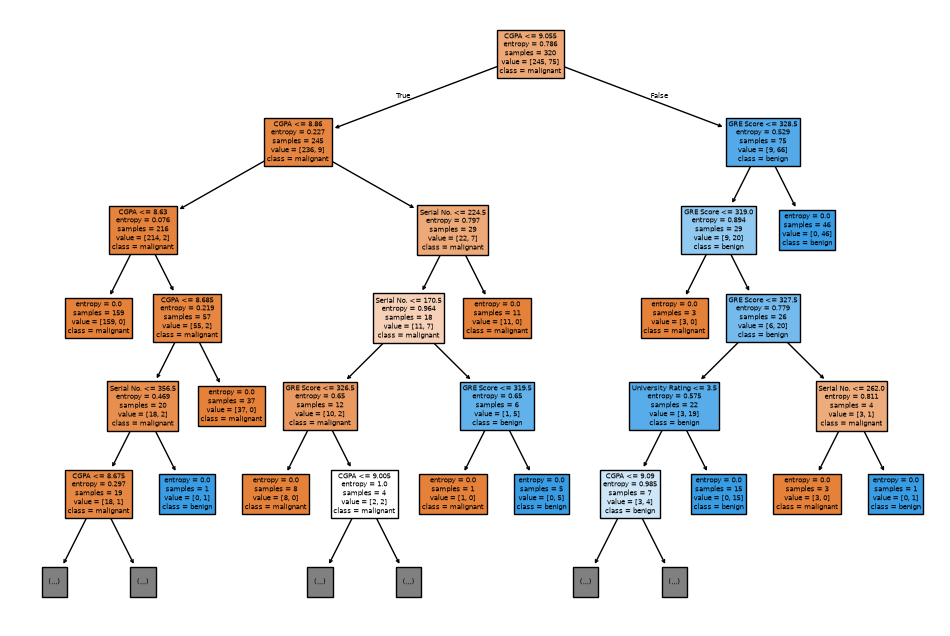

In [63]:
plt.figure(figsize = (12,8))
plot_tree(
    tree2,
    max_depth = 5,
    feature_names = X.columns,
    class_names = ["malignant", "benign"], filled=True
)
plt.show()

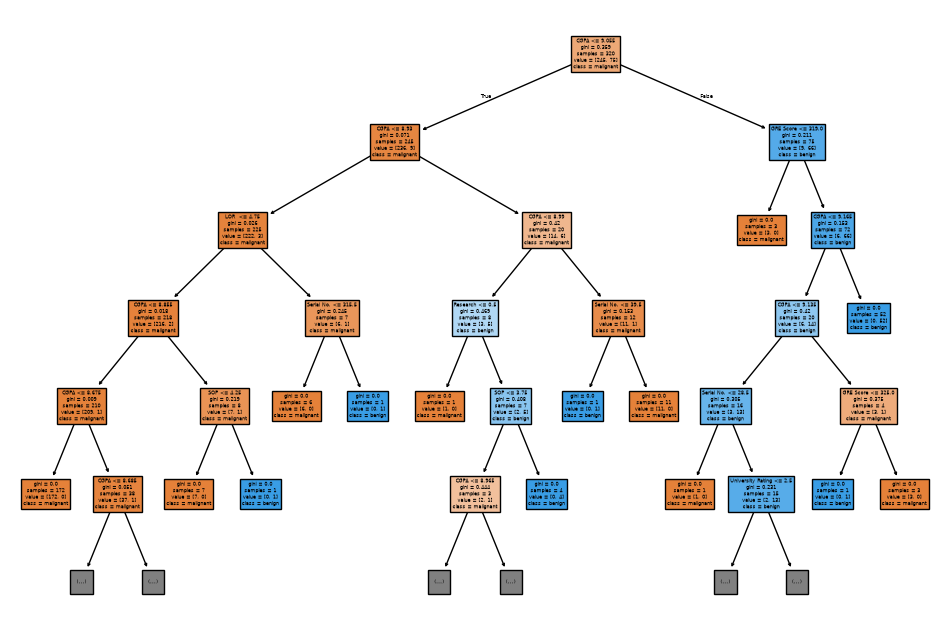

In [64]:
plt.figure(figsize = (12,8))
plot_tree(
    tree1,
    max_depth = 5,
    feature_names = X.columns,
    class_names = ["malignant", "benign"], filled=True
)
plt.show()

In [65]:
if f1_score(y_test, pred_tree) > f1_score(y_test, pred_nb):
    print("Best model is Decision Tree.")
else:
    print("Best Model is Naive Bayes.")

Best Model is Naive Bayes.
